# Week 2 Day 1 — Data Visualisation

## Objective
Create five professional charts with Matplotlib and Seaborn using real sales data.

Dataset: `sales_data.csv`


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
CHART_DIR = Path("charts")
CHART_DIR.mkdir(exist_ok=True)

df = pd.read_csv("../../week-01/day-05/sales_data.csv")
df["sale_date"] = pd.to_datetime(df["sale_date"])

df.head()


,sale_id,customer_name,product,category,region,amount,sale_date,discount
0,1,Ananya,Laptop,Electronics,South,55000.0,2026-09-01,0.10
1,2,Rahul,Phone,Electronics,North,25000.0,2026-09-02,0.05
2,3,Priya,Chair,Furniture,West,4500.0,2026-09-03,NaN
3,4,Arjun,Desk,Furniture,South,8000.0,2026-09-04,0.00
4,5,Meera,Headphones,Electronics,East,2000.0,2026-09-05,0.15


## 1. Line chart — sales over time

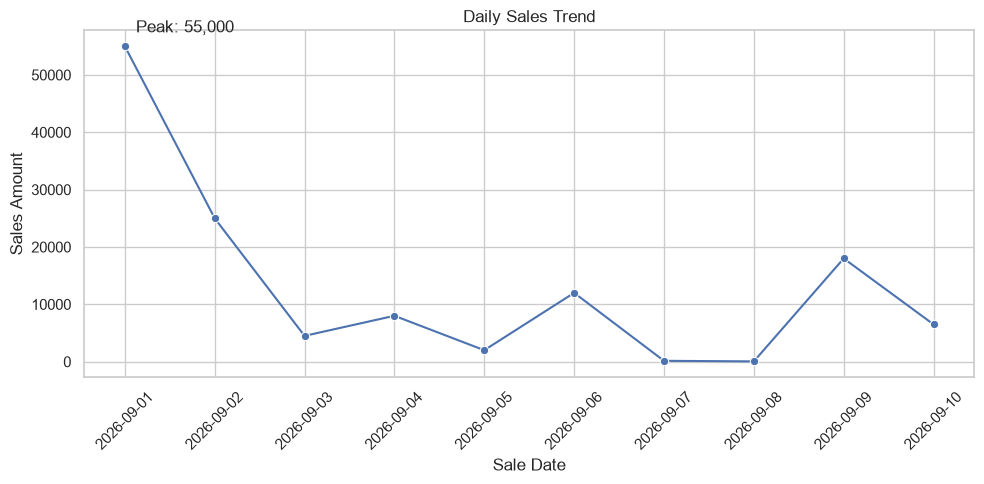

In [2]:
daily_sales = df.groupby("sale_date", as_index=False)["amount"].sum()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=daily_sales, x="sale_date", y="amount", marker="o", ax=ax)
ax.set(title="Daily Sales Trend", xlabel="Sale Date", ylabel="Sales Amount")
ax.tick_params(axis="x", rotation=45)
peak = daily_sales.loc[daily_sales["amount"].idxmax()]
ax.annotate(f"Peak: {peak['amount']:,.0f}",
            (peak["sale_date"], peak["amount"]),
            xytext=(8, 10), textcoords="offset points")
fig.tight_layout()
fig.savefig(CHART_DIR / "01_line_chart.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Bar chart — total sales by category

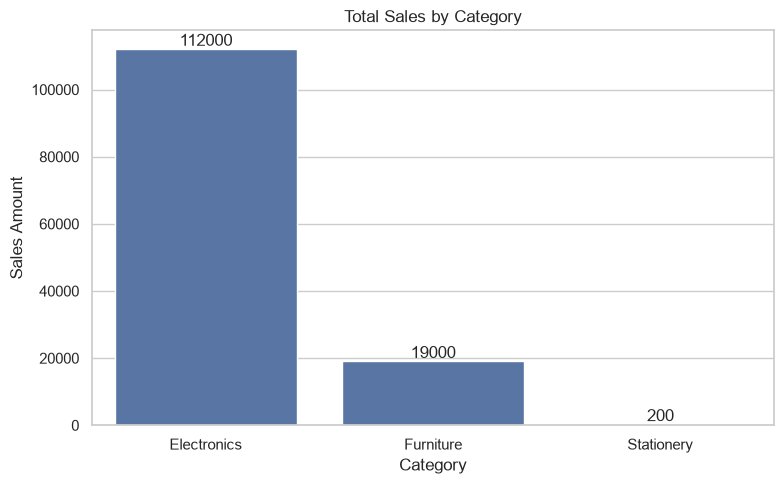

In [3]:
category_sales = df.groupby("category", as_index=False)["amount"].sum()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=category_sales, x="category", y="amount", ax=ax)
ax.set(title="Total Sales by Category", xlabel="Category", ylabel="Sales Amount")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
fig.tight_layout()
fig.savefig(CHART_DIR / "02_bar_chart.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Scatter plot — discount versus sales amount

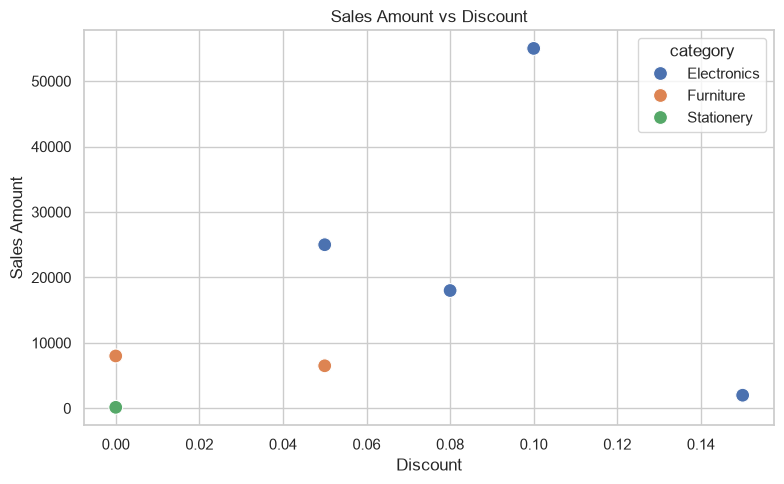

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="discount", y="amount", hue="category", s=100, ax=ax)
ax.set(title="Sales Amount vs Discount", xlabel="Discount", ylabel="Sales Amount")
fig.tight_layout()
fig.savefig(CHART_DIR / "03_scatter_chart.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Histogram — distribution of sales amounts

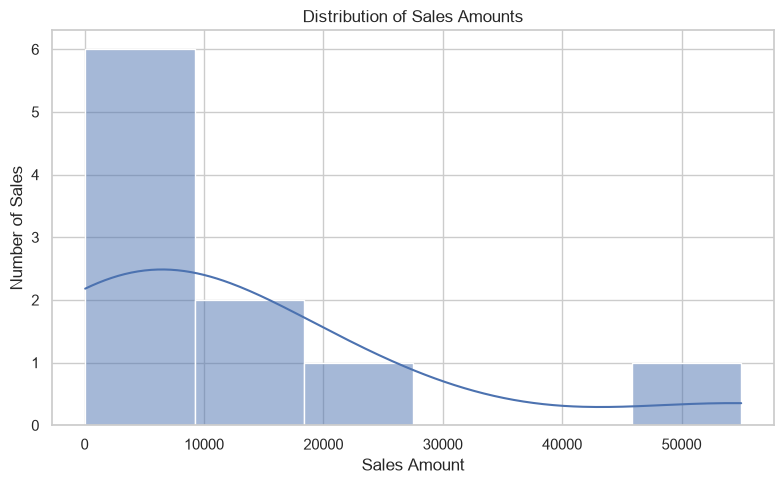

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="amount", bins=6, kde=True, ax=ax)
ax.set(title="Distribution of Sales Amounts", xlabel="Sales Amount", ylabel="Number of Sales")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_histogram.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Box plot — sales amounts by category

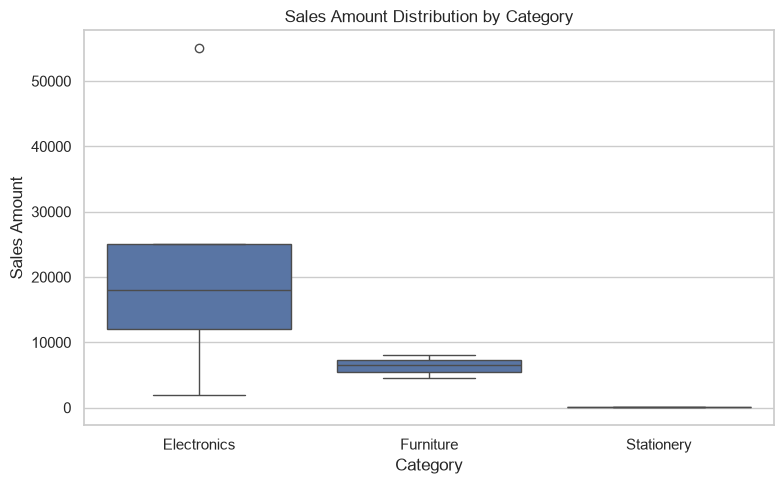

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="category", y="amount", ax=ax)
ax.set(title="Sales Amount Distribution by Category",
       xlabel="Category", ylabel="Sales Amount")
fig.tight_layout()
fig.savefig(CHART_DIR / "05_box_plot.png", dpi=150, bbox_inches="tight")
plt.show()


## Key chart-selection notes

- **Line chart:** trends over time.
- **Bar chart:** compares categories.
- **Scatter plot:** explores relationships between two numeric variables.
- **Histogram:** shows the distribution of one numeric variable.
- **Box plot:** compares distributions and highlights potential outliers.

Matplotlib provides detailed chart controls; Seaborn adds convenient statistical plotting and styling.
